# 13a — New datasets: prepare them

**Question of this step (notebooks 13a and 13b):** *do our detectors still work with a camera, a room and people they have never seen?*

Until now everything comes from **URFD**. We add three test sets:

| Dataset | Camera | Videos |
|---|---|---|
| **URFD camera 1** | on the **ceiling** (the same 30 falls as camera 0) | 30 falls, no daily activity |
| **GMDCSA-24** | side view, real homes | 79 falls, 81 daily activities |
| **CAUCAFall** | high corner, wide angle | 50 falls, 50 daily activities |

This notebook only **prepares** the data, exactly as in URFD (person box of notebook 03, skeleton of notebook 09). The tests are in notebook 13b.

In [1]:
from pathlib import Path
import csv, re
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import mediapipe as mp
from mediapipe.tasks.python import vision, BaseOptions

RAW = Path("..") / "data" / "raw"
PROC = Path("..") / "data" / "processed"
NEW = PROC / "new"; (NEW / "skeletons").mkdir(parents=True, exist_ok=True); (NEW / "boxes").mkdir(exist_ok=True)
MODEL = Path("..") / "models" / "pose_landmarker_full.task"
SETS = ["URFD cam0", "URFD cam1", "GMDCSA-24", "CAUCAFall"]

💡 **Interpretation:** setup only: paths, MediaPipe and the names of the 4 test sets. All the results of this notebook are saved in `data/processed/new/`.

## Step 1 — One table with all the videos

For every video we need: the **dataset**, the **person**, fall or daily activity (ADL), the number of images per second (**fps**) and, for a fall, the **onset** = the moment the fall starts, in seconds:

- **URFD:** first frame with label 0 (*falling*). Camera 1 is synchronised with camera 0, so it has the same onset.
- **GMDCSA-24:** the start of the `Falling (...)[a to b]` phase in `Fall.csv`.
- **CAUCAFall:** the first image with class 1 (*fall*).

We also choose the **fold** of each video (used in 13b to choose the settings): the same **person** is never in two folds. GMDCSA subjects 2 and 3 share the same room, so they share the same fold.

In [2]:
def number(path): return int(re.search(r"(\d+)\D*$", path.stem).group(1))

def png_list(folder): return sorted(folder.rglob("*.png"), key=number)

strict_of = pd.read_csv(Path("..") / "video_groups.csv").set_index("video").group.to_dict()
labels = pd.concat([pd.read_csv(RAW / "urfd" / "labels" / f"urfall-cam0-{k}.csv", header=None, usecols=[0, 1, 2]) for k in ["falls", "adls"]])
labels.columns = ["video", "frame", "frame_label"]
urfd_onset = labels[labels.video.str.startswith("fall") & (labels.frame_label == 0)].groupby("video").frame.min()

rows, odd = [], []
for v, fold in strict_of.items():                                                          # URFD
    onset = (urfd_onset[v] - 1) / 30 if v.startswith("fall") else np.nan
    for cam in [0] + [1] * v.startswith("fall"):
        folder = RAW / "urfd" / ("rgb" if cam == 0 else "rgb_cam1") / v
        rows.append({"dataset": f"URFD cam{cam}", "video": f"cam{cam}-{v}", "person": f"group {fold}", "kind": v[:4].rstrip("-"), "activity": v[:4].rstrip("-"),
                     "light": "", "fold": fold, "fps": 30.0, "frames": len(png_list(folder)), "onset": onset, "path": folder.relative_to(RAW).as_posix()})

PHASE = re.compile(r"Fall(?:ing)?\s*\(\w+\)?\s*\[\s*([\d.]+)\s*(?:to)?\s*([\d.]+)\s*\]")   # accepts the rows written a little differently
for s in range(1, 5):                                                                      # GMDCSA-24
    for kind in ["Fall", "ADL"]:
        for r in list(csv.reader(open(RAW / "gmdcsa24" / f"Subject {s}" / f"{kind}.csv", encoding="utf-8-sig", errors="replace")))[1:]:
            if not r: continue
            path = RAW / "gmdcsa24" / f"Subject {s}" / kind / r[0].strip()
            cap = cv2.VideoCapture(str(path)); onset = np.nan
            if kind == "Fall":
                m = PHASE.search(r[-1])
                onset = float(m.group(1)) if m else np.nan
                if not m:                                                                  # no time given: the fall starts when the phase before it ends
                    onset = float(re.search(r"\[[\d.]+ to ([\d.]+)\]", r[-1]).group(1)); odd.append(f"subject {s} {r[0]}: no time for the fall ({r[-1].strip()}), we take {onset} s")
            rows.append({"dataset": "GMDCSA-24", "video": f"gmd-s{s}-{kind.lower()}-{r[0][:2]}", "person": f"subject {s}", "kind": kind.lower(),
                         "activity": kind.lower() if kind == "Fall" else " + ".join(sorted(set(re.findall(r"([A-Za-z]+)\s*\[", r[-1])))),
                         "light": r[2].strip(), "fold": {1: 1, 2: 2, 3: 2, 4: 3}[s], "fps": cap.get(cv2.CAP_PROP_FPS),
                         "frames": int(cap.get(cv2.CAP_PROP_FRAME_COUNT)), "onset": onset, "path": path.relative_to(RAW).as_posix()})

def cauca_class(png):                                                                      # 0 no fall, 1 fall, None = no label file
    txt = png.with_suffix(".txt")
    return int(txt.read_text().split()[0]) if txt.exists() else None

for s in range(1, 11):                                                                     # CAUCAFall
    for folder in sorted(p for p in (RAW / "caucafall" / f"Subject.{s}").iterdir() if p.is_dir()):
        pngs = png_list(folder); classes = [cauca_class(p) for p in pngs]
        if None in classes: odd.append(f"Subject.{s} {folder.name}: {classes.count(None)} image without label")
        kind = "fall" if folder.name.startswith("Fall") else "adl"
        rows.append({"dataset": "CAUCAFall", "video": f"cau-s{s:02d}-{folder.name.lower().replace(' ', '-')}", "person": f"subject {s}", "kind": kind, "activity": folder.name,
                     "light": "", "fold": (s - 1) % 5 + 1, "fps": 20.0, "frames": len(pngs), "onset": classes.index(1) / 20 if kind == "fall" else np.nan,
                     "path": folder.relative_to(RAW).as_posix()})

videos = pd.DataFrame(rows)
print("\n".join(odd))
videos["seconds"] = videos.frames / videos.fps
videos.groupby(["dataset", "kind"], sort=False).agg(videos=("video", "size"), persons=("person", "nunique"), fps_min=("fps", "min"), fps_max=("fps", "max"),
    seconds_min=("seconds", "min"), seconds_median=("seconds", "median"), seconds_max=("seconds", "max"), onset_median=("onset", "median")).round(1)

subject 4 15.mp4: no time for the fall (Falling (FW); Sitting[0 to 1.7]), we take 1.7 s
Subject.2 Fall backwards: 1 image without label
Subject.5 Kneel: 1 image without label
Subject.6 Walk: 1 image without label
Subject.8 Hop: 1 image without label
Subject.8 Pick up object: 1 image without label
Subject.9 Walk: 1 image without label


videos  persons  fps_min  fps_max  seconds_min  \
dataset   kind                                                   
URFD cam0 adl       40        5     30.0     30.0          2.3   
          fall      30        5     30.0     30.0          1.8   
URFD cam1 fall      30        5     30.0     30.0          1.8   
GMDCSA-24 fall      79        4     15.0     29.9          3.0   
          adl       81        4     15.0     29.9          3.3   
CAUCAFall fall      50       10     20.0     20.0          4.4   
          adl       50       10     20.0     20.0          5.6   

                seconds_median  seconds_max  onset_median  
dataset   kind                                             
URFD cam0 adl              7.8         13.3           NaN  
          fall             3.1          7.2           0.9  
URFD cam1 fall             3.1          7.2           0.9  
GMDCSA-24 fall             6.1         15.5           2.0  
          adl              9.4         17.5           NaN  
CAUCAFall fall            10.2         14.4           3.0  
          adl             10.6         14.6           NaN

💡 **Interpretation:** **360 videos** with very different rates (15 to 30 images/s) and lengths (1.8 to 17.5 s). A model must use seconds, not numbers of images.
One GMDCSA fall has **no time** in the file (we take the end of *Sitting*, 1.7 s) and 6 CAUCAFall images have no label; all the others were read.

## Step 2 — Look at them

One fall of each dataset: the image **0.5 s before** the onset, at **+0.7 s** and at **+1.8 s** (or the last one if the video is shorter).

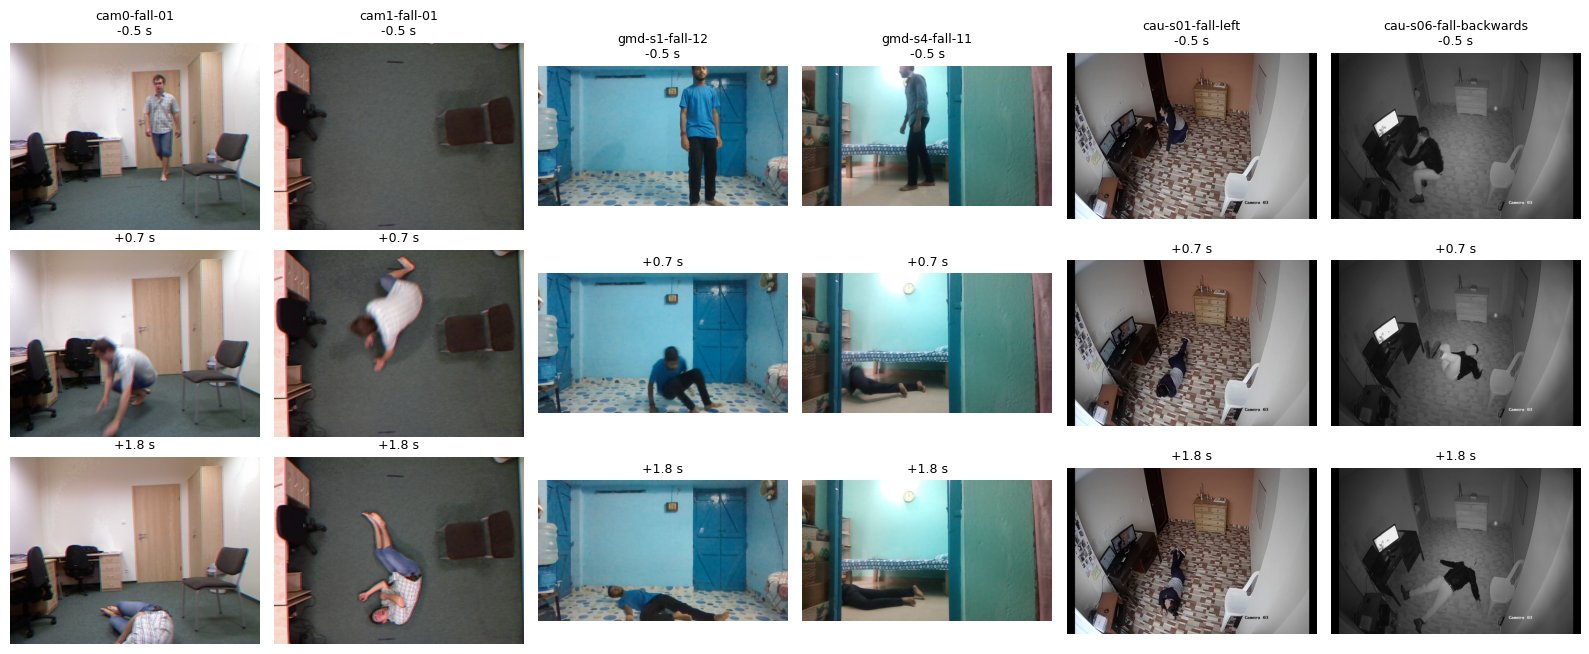

In [3]:
def images_of(r):
    """All the images of a video, in order (BGR)."""
    path = RAW / r.path
    if path.suffix == ".mp4":
        cap = cv2.VideoCapture(str(path))
        while True:
            ok, image = cap.read()
            if not ok: return
            yield image
    else:
        for p in png_list(path): yield cv2.imread(str(p))

def image_at(r, t):
    images = list(images_of(r)); return images[int(np.clip(round(t * r.fps), 0, len(images) - 1))]

show = ["cam0-fall-01", "cam1-fall-01", "gmd-s1-fall-12", "gmd-s4-fall-11", "cau-s01-fall-left", "cau-s06-fall-backwards"]
by_name = videos.set_index("video", drop=False)
fig, axes = plt.subplots(3, 6, figsize=(16, 6.6))
for col, v in enumerate(show):
    r = by_name.loc[v]
    for row, dt in enumerate([-0.5, 0.7, 1.8]):
        axes[row, col].imshow(cv2.cvtColor(image_at(r, max(r.onset + dt, 0)), cv2.COLOR_BGR2RGB)); axes[row, col].axis("off")
        axes[row, col].set_title(f"{v}\n{dt:+.1f} s" if row == 0 else f"{dt:+.1f} s", fontsize=9)
plt.tight_layout(); plt.show()

💡 **Interpretation:** the same kind of fall looks very different: from the **side** (URFD, GMDCSA), from a **high corner** (CAUCAFall, sometimes in grey) and from **above** (camera 1).
In `cam1-fall-01` nobody is visible 0.5 s before the fall; in `gmd-s4-fall-11` a wall hides the upper body at the end.

## Step 3 — Find the person (the method of notebook 03)

Same code as notebook 03: background = **median image**, difference > 25, opening + closing, largest region. Two small adaptations:

- every image is first resized to a **height of 480** (the height of URFD), so the same thresholds have the same meaning;
- we keep **10 images per second** in every dataset (URFD: 1 image out of 3; CAUCAFall: 1 out of 2). Neighbouring images are almost identical, and all the methods will then see the same rate.

The result is saved, one small file per video.

In [4]:
THRESHOLD, MIN_AREA = 25, 800
KERNEL = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (5, 5))

def height480(image):
    h, w = image.shape[:2]
    return image if h == 480 else cv2.resize(image, (round(w * 480 / h), 480), interpolation=cv2.INTER_AREA)

def grid_of(n, fps):
    """10 images per second: the nearest image of t = 0, 0.1, 0.2 ... seconds."""
    return np.unique(np.round(np.arange(0, (n - 1) / fps + 1e-6, 0.1) * fps).astype(int))

def background_of(images, fps):
    step = max(1, round(fps / 6))                                                          # about 6 images per second, as in notebook 03
    return np.median(np.stack([cv2.GaussianBlur(im, (5, 5), 0) for im in images[::step]]), axis=0).astype(np.uint8)

def box_of(image, bg):
    diff = cv2.absdiff(cv2.GaussianBlur(image, (5, 5), 0), bg).max(axis=2)
    mask = cv2.morphologyEx((diff > THRESHOLD).astype(np.uint8) * 255, cv2.MORPH_OPEN, KERNEL)
    mask = cv2.morphologyEx(mask, cv2.MORPH_CLOSE, KERNEL, iterations=2)
    contours = [c for c in cv2.findContours(mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)[0] if cv2.contourArea(c) > MIN_AREA]
    return cv2.boundingRect(max(contours, key=cv2.contourArea)) if contours else (np.nan,) * 4

def crop_person(image, box, size):                                                         # notebooks 03 and 04
    x, y, w, h = box
    side = int(max(w, h) * 1.1)
    cx, cy = x + w // 2, y + h // 2
    padded = cv2.copyMakeBorder(image, side, side, side, side, cv2.BORDER_CONSTANT, value=0)
    x0, y0 = cx - side // 2 + side, cy - side // 2 + side
    return cv2.resize(padded[y0:y0 + side, x0:x0 + side], (size, size))

def prepare_boxes(r):
    """Boxes and crops (64 and 128 pixels) of a video; saved in data/processed/new/boxes."""
    file = NEW / "boxes" / f"{r.video}.npz"
    if not file.exists():
        images = [height480(im) for im in images_of(r)]
        bg, grid = background_of(images, r.fps), grid_of(len(images), r.fps)
        boxes = np.array([box_of(images[i], bg) for i in grid], float)
        good = ~np.isnan(boxes[:, 0])
        crops = {f"crops{size}": np.array([crop_person(cv2.cvtColor(images[i], cv2.COLOR_BGR2RGB), b.astype(int), size) for i, b in zip(grid[good], boxes[good])],
                                          np.uint8).reshape(-1, size, size, 3) for size in (64, 128)}
        np.savez_compressed(file, index=grid, boxes=boxes, width=images[0].shape[1], frames=len(images), **crops)
    return file

for r in videos.itertuples(): prepare_boxes(r)

parts = []
for r in videos.itertuples():
    z = np.load(NEW / "boxes" / f"{r.video}.npz")
    d = pd.DataFrame(z["boxes"], columns=["x", "y", "w", "h"]).assign(video=r.video, dataset=r.dataset, person=r.person, kind=r.kind, fold=r.fold, index=z["index"], width=int(z["width"]), read=int(z["frames"]))
    d["t"] = d["index"] / r.fps; d["onset"] = r.onset
    parts.append(d)
frames = pd.concat(parts, ignore_index=True)
frames["box_found"] = frames.x.notna()
frames["moment"] = np.where(frames.kind == "adl", "ADL", np.where(frames.t < frames.onset, "before the fall", "from the fall"))
read = frames.groupby("video").read.first().loc[videos.video].to_numpy()
print("images kept:", len(frames), "| videos where the file announces a different number of images:", int((read != videos.frames).sum()), "| biggest difference:", int(np.abs(read - videos.frames).max()))
frames.pivot_table(index="dataset", columns="moment", values="box_found").loc[SETS].round(2)

images kept: 27941 | videos where the file announces a different number of images: 0 | biggest difference: 0


moment,ADL,before the fall,from the fall
dataset,,,
URFD cam0,0.92,1.00,1.00
URFD cam1,NaN,0.62,0.98
GMDCSA-24,0.86,1.00,0.78
CAUCAFall,0.99,1.00,0.88


💡 **Interpretation:** people are almost always boxed before the fall (100%), but only **78%** in GMDCSA from the fall on. Checked: the box is found in **100%** of the late images when the person lies for less than half of the clip, and in **47%** when it is more than 60%: a person who does not move becomes part of the *median background*.
For the images that matter (0.5 to 2 s after the aligned start of Step 5) it is found in 95 to 100% everywhere. Camera 1: 62% before the fall, because the person often enters the view just before.

### Is the box really on the person?

A box is not useful if it is on a shadow or a door. Two checks:
1. **CAUCAFall** gives the true box of the person in every image. We measure the **overlap** (*IoU* = common area / total area: 1 = perfect, 0 = nothing in common). These true boxes are used **only for this check**: a real system does not have them.
2. Everywhere: is the box **too big** (more than half of the image)? That means the whole image changed (light, camera that moves).

In [5]:
def iou(a, b):
    x0, y0, x1, y1 = max(a[0], b[0]), max(a[1], b[1]), min(a[0] + a[2], b[0] + b[2]), min(a[1] + a[3], b[1] + b[3])
    inter = max(x1 - x0, 0) * max(y1 - y0, 0)
    return inter / (a[2] * a[3] + b[2] * b[3] - inter)

frames["iou"] = np.nan
for v, d in frames[frames.dataset == "CAUCAFall"].groupby("video"):
    pngs = png_list(RAW / by_name.loc[v].path)
    for i, r in d.iterrows():
        txt = pngs[r["index"]].with_suffix(".txt")
        if r.box_found and txt.exists():
            cx, cy, w, h = [float(q) for q in txt.read_text().split()[1:5]]
            frames.loc[i, "iou"] = iou((r.x, r.y, r.w, r.h), ((cx - w / 2) * r.width, (cy - h / 2) * 480, w * r.width, h * 480))
c = frames[(frames.dataset == "CAUCAFall") & frames.iou.notna()]
print("CAUCAFall, overlap with the true box | median:", round(c.iou.median(), 2), "| above 0.5:", f"{(c.iou > 0.5).mean():.0%}", "| below 0.1 (box on something else):", f"{(c.iou < 0.1).mean():.0%}")
print(c.groupby("moment").iou.agg(median="median", above_half=lambda s: (s > 0.5).mean(), below_01=lambda s: (s < 0.1).mean()).round(2))
frames["too_big"] = frames.w * frames.h > 0.5 * frames.width * 480
print("\nboxes bigger than half of the image:", frames[frames.box_found].groupby("dataset").too_big.mean().loc[SETS].round(3).to_dict())
c.groupby("person").iou.median().round(2).to_frame("median overlap").T

CAUCAFall, overlap with the true box | median: 0.51 | above 0.5: 51% | below 0.1 (box on something else): 4%
                 median  above_half  below_01
moment                                       
ADL                0.59        0.62      0.01
before the fall    0.45        0.42      0.07
from the fall      0.36        0.36      0.07

boxes bigger than half of the image: {'URFD cam0': 0.0, 'URFD cam1': 0.0, 'GMDCSA-24': 0.024, 'CAUCAFall': 0.0}


person,subject 1,subject 10,subject 2,subject 3,subject 4,subject 5,subject 6,subject 7,subject 8,subject 9
median overlap,0.66,0.5,0.67,0.6,0.66,0.46,0.5,0.44,0.33,0.47


💡 **Interpretation:** on CAUCAFall the box overlaps the true box **0.51** in the median, and only 4% of the boxes are on something else. It is worse **from the fall on (0.36)** than in ADLs (0.59): the box often covers only a part of a fallen person.
Only GMDCSA has some boxes bigger than half of the image (2.4%).

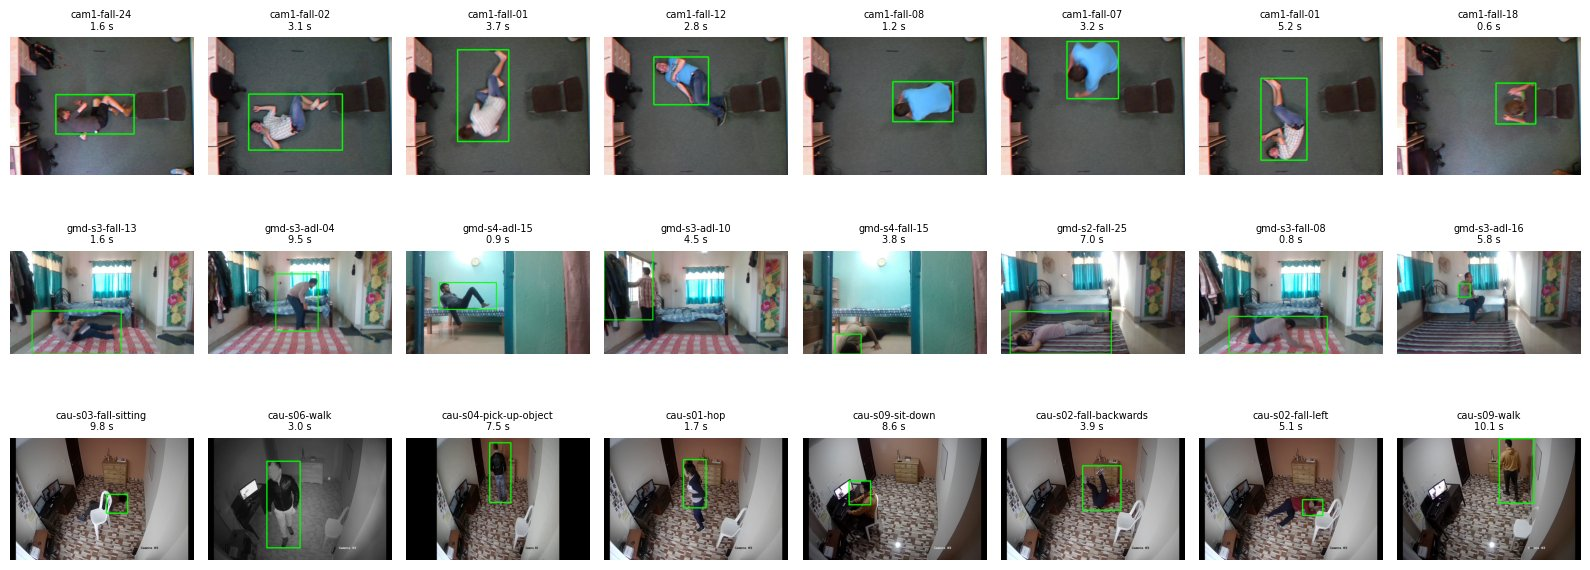

In [6]:
rng = np.random.default_rng(0)
fig, axes = plt.subplots(3, 8, figsize=(16, 6.4))
for row, name in enumerate(SETS[1:]):
    d = frames[(frames.dataset == name) & frames.box_found & (frames.moment != "before the fall")]
    for ax, i in zip(axes[row], rng.choice(d.index, 8, replace=False)):
        r = frames.loc[i]
        image = height480(image_at(by_name.loc[r.video], r.t)); cv2.rectangle(image, (int(r.x), int(r.y)), (int(r.x + r.w), int(r.y + r.h)), (0, 255, 0), 4)
        ax.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB)); ax.axis("off"); ax.set_title(f"{r.video}\n{r.t:.1f} s", fontsize=7)
plt.tight_layout(); plt.show()

💡 **Interpretation:** most boxes are on the person, also from the ceiling. Typical errors: the box takes only a **part** of the body (`gmd-s4-fall-15`, `gmd-s3-adl-16`) or a **chair that moved** together with the legs (`cau-s02-fall-left`, `cau-s03-fall-sitting`).

## Step 4 — Skeletons (the method of notebook 09)

MediaPipe in VIDEO mode, on **all** the images (so it can follow the person), with the true time of every image. We keep the 13 joints of notebook 12. URFD camera 0 was already done in notebook 09.

In [7]:
J = {"nose": 0, "l_shoulder": 11, "r_shoulder": 12, "l_elbow": 13, "r_elbow": 14, "l_wrist": 15, "r_wrist": 16, "l_hip": 23, "r_hip": 24,
     "l_knee": 25, "r_knee": 26, "l_ankle": 27, "r_ankle": 28}

def prepare_skeleton(r):
    """13 joints (x, y in 0..1) of every image of a video; NaN = nobody found. Saved in data/processed/new/skeletons."""
    file = NEW / "skeletons" / f"{r.video}.npy"
    if not file.exists():
        options = vision.PoseLandmarkerOptions(base_options=BaseOptions(model_asset_path=str(MODEL)), running_mode=vision.RunningMode.VIDEO, num_poses=1)
        out = []
        with vision.PoseLandmarker.create_from_options(options) as detector:
            for i, image in enumerate(images_of(r)):
                result = detector.detect_for_video(mp.Image(image_format=mp.ImageFormat.SRGB, data=cv2.cvtColor(image, cv2.COLOR_BGR2RGB)), int(i * 1000 / r.fps))
                out.append([[result.pose_landmarks[0][k].x, result.pose_landmarks[0][k].y] for k in J.values()] if result.pose_landmarks else np.full((13, 2), np.nan))
        np.save(file, np.array(out, np.float32))
    return file

old = pd.read_csv(PROC / "skeletons.csv").sort_values(["video", "frame"])                  # notebook 09
for v, d in old.groupby("video"):
    file = NEW / "skeletons" / f"cam0-{v}.npy"
    if not file.exists(): np.save(file, np.stack([d[[f"{j}_x", f"{j}_y"]].to_numpy() for j in J], 1).astype(np.float32))
for r in videos.itertuples(): prepare_skeleton(r)

frames["skeleton_found"] = False
for v, d in frames.groupby("video"):
    frames.loc[d.index, "skeleton_found"] = ~np.isnan(np.load(NEW / "skeletons" / f"{v}.npy")[d["index"], 0, 0])
table = frames.pivot_table(index="dataset", columns="moment", values="skeleton_found").loc[SETS].round(2)
after = frames[(frames.t >= frames.onset + 0.5) & (frames.t <= frames.onset + 2)]
table["from +0.5 s to +2 s"] = after.groupby("dataset").skeleton_found.mean().round(2)
table

moment,ADL,before the fall,from the fall,from +0.5 s to +2 s
dataset,,,,
URFD cam0,0.78,1.00,0.89,0.85
URFD cam1,NaN,0.41,0.87,0.94
GMDCSA-24,0.99,0.98,0.89,0.93
CAUCAFall,0.91,0.80,0.91,0.93


💡 **Interpretation:** in the images that matter (0.5 to 2 s after the onset), MediaPipe finds a skeleton in **85 to 94%** of the images, even from the ceiling (94%).
Found does not mean correct: see the next pictures.

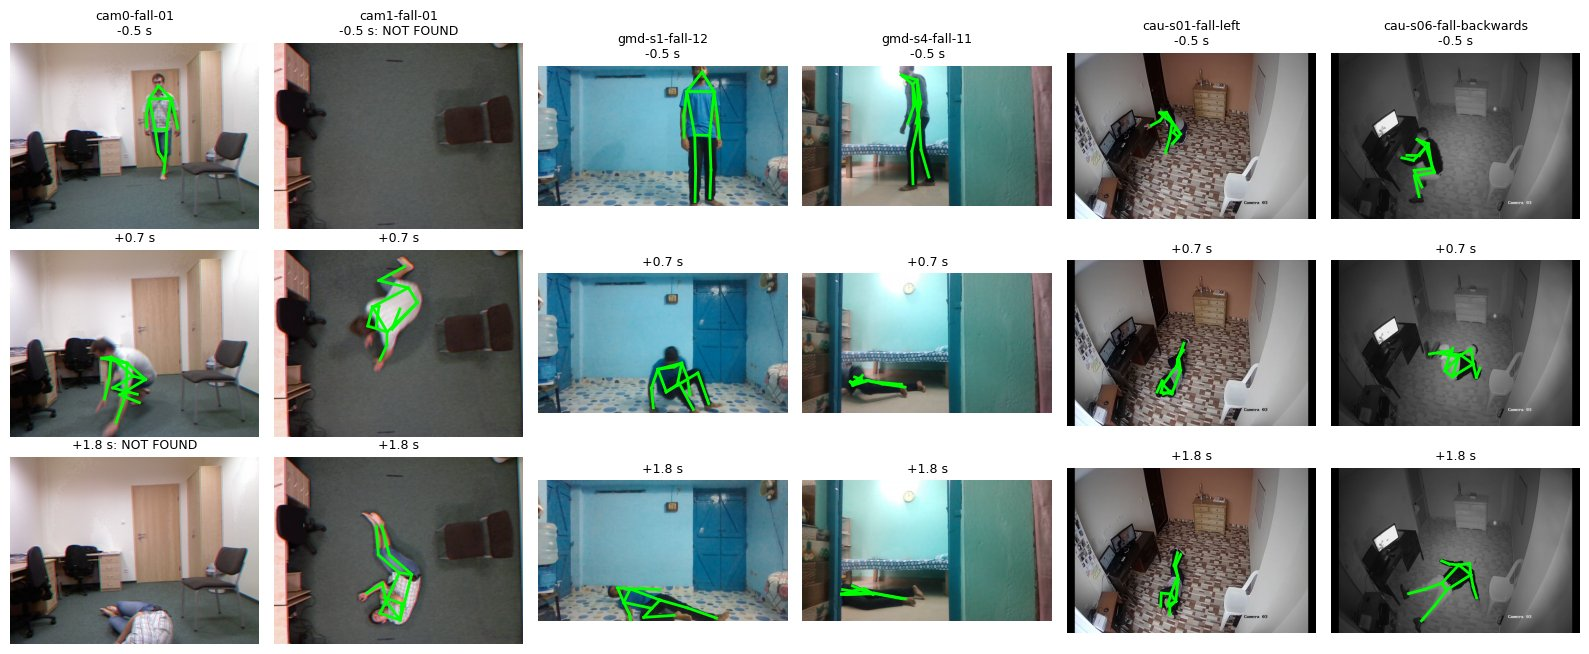

In [8]:
BONES = [(0, 1), (0, 2), (1, 2), (1, 3), (3, 5), (2, 4), (4, 6), (1, 7), (2, 8), (7, 8), (7, 9), (9, 11), (8, 10), (10, 12)]
fig, axes = plt.subplots(3, 6, figsize=(16, 6.6))
for col, v in enumerate(show):
    r = by_name.loc[v]; P = np.load(NEW / "skeletons" / f"{v}.npy")
    for row, dt in enumerate([-0.5, 0.7, 1.8]):
        i = int(np.clip(round(max(r.onset + dt, 0) * r.fps), 0, len(P) - 1)); image = image_at(r, i / r.fps); ax = axes[row, col]
        ax.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB)); ax.axis("off")
        q = P[i] * [image.shape[1], image.shape[0]]
        for a, b in BONES: ax.plot(q[[a, b], 0], q[[a, b], 1], color="lime", lw=2)
        ax.set_xlim(0, image.shape[1]); ax.set_ylim(image.shape[0], 0)
        ax.set_title((f"{v}\n" if row == 0 else "") + f"{dt:+.1f} s" + ("" if not np.isnan(q[0, 0]) else ": NOT FOUND"), fontsize=9)
plt.tight_layout(); plt.show()

💡 **Interpretation:** the skeletons follow the body well in GMDCSA and CAUCAFall, also in grey images, and even from the ceiling in `cam1-fall-01`.
Nobody is found in `cam0-fall-01` at +1.8 s (lying, as in notebook 09) and in `cam1-fall-01` before the person is in the view.

## Step 5 — Is the *onset* the same moment in all the datasets?

Each dataset was labelled by other people. We check it without any detector: in each fall video, when is the **fastest drop** of the body (middle of shoulders and hips, over 0.3 s), compared with the official onset? If the onsets mean the same thing, this delay is the same everywhere.

In [9]:
def fastest_drop(r):
    """Moment of the fastest drop, in seconds after the official onset (searched within 2.5 s of it)."""
    P = np.load(NEW / "skeletons" / f"{r.video}.npy").astype(float)
    height = pd.Series(1 - (P[:, 7:9, 1].mean(1) + P[:, 1:3, 1].mean(1)) / 2).interpolate(limit=int(r.fps / 2), limit_area="inside").rolling(max(3, round(r.fps / 6) | 1), center=True, min_periods=1).median()
    half = max(1, round(r.fps * 0.15)); drop = (height.shift(half) - height.shift(-half)).to_numpy(); t = np.arange(len(height)) / r.fps
    near = np.flatnonzero((np.abs(t - r.onset) <= 2.5) & ~np.isnan(drop))
    return t[near[np.argmax(drop[near])]] - r.onset if len(near) else np.nan

falls = videos[videos.kind == "fall"].copy()
falls["delay"] = [fastest_drop(r) for r in falls.itertuples()]
delay = falls.groupby("dataset").delay.describe(percentiles=[0.25, 0.5, 0.75]).loc[SETS, ["25%", "50%", "75%"]].round(2)
shift = (delay["50%"] - delay.loc["URFD cam0", "50%"]).round(1)
shift["URFD cam1"] = 0.0                                                                   # camera 1 is synchronised with camera 0: the same moments
delay["shift of the start (s)"] = shift
videos["start"] = (videos.onset + videos.dataset.map(shift)).clip(lower=0)
frames["start"] = frames.video.map(videos.set_index("video").start)
print("fastest drop BEFORE the official onset:", falls[falls.delay < 0].groupby("dataset").size().reindex(SETS, fill_value=0).to_dict(), "| falls:", falls.groupby("dataset").size().loc[SETS].to_dict())
delay

fastest drop BEFORE the official onset: {'URFD cam0': 0, 'URFD cam1': 4, 'GMDCSA-24': 2, 'CAUCAFall': 43} | falls: {'URFD cam0': 30, 'URFD cam1': 30, 'GMDCSA-24': 79, 'CAUCAFall': 50}


,25%,50%,75%,shift of the start (s)
dataset,,,,
URFD cam0,0.70,0.77,0.86,0.0
URFD cam1,0.61,0.77,0.96,0.0
GMDCSA-24,0.26,0.42,0.58,-0.4
CAUCAFall,-0.80,-0.55,-0.20,-1.3


💡 **Interpretation:** the onsets are **not the same moment**: the fastest drop comes **0.77 s after** it in URFD, 0.42 s after in GMDCSA, but **0.55 s before** it in CAUCAFall (in 43 of 50 falls). CAUCAFall says *fall* when the person is already down.
Without a correction, the fall itself would be taught as *no fall* in CAUCAFall, and an alarm during the fall would be called *early*. Shifts: 0 s, **−0.4 s** (GMDCSA) and **−1.3 s** (CAUCAFall).

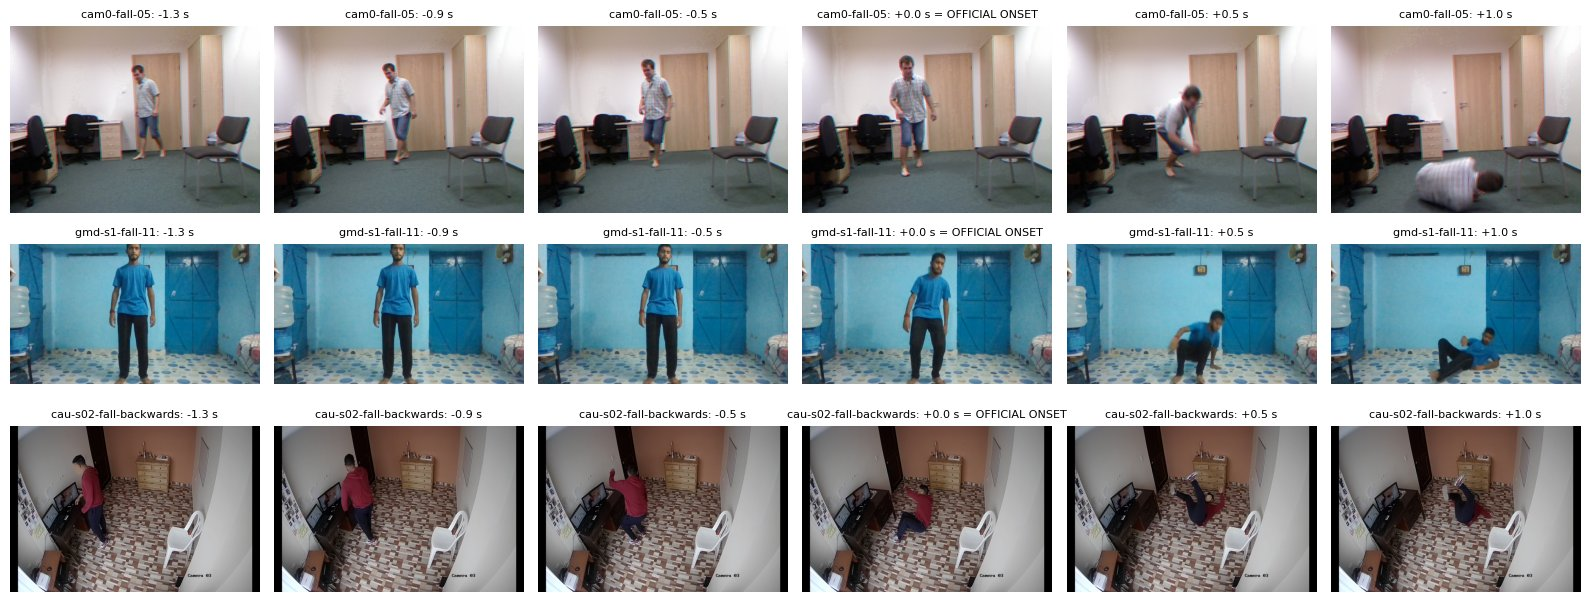

In [10]:
fig, axes = plt.subplots(3, 6, figsize=(16, 6.2))
for row, v in enumerate(["cam0-fall-05", "gmd-s1-fall-11", "cau-s02-fall-backwards"]):
    r = videos[videos.video == v].iloc[0]
    for ax, dt in zip(axes[row], [-1.3, -0.9, -0.5, 0, 0.5, 1.0]):
        ax.imshow(cv2.cvtColor(image_at(r, max(r.onset + dt, 0)), cv2.COLOR_BGR2RGB)); ax.axis("off")
        ax.set_title(f"{v}: {dt:+.1f} s" + (" = OFFICIAL ONSET" if dt == 0 else ""), fontsize=8)
plt.tight_layout(); plt.show()

💡 **Interpretation:** the pictures agree: at the official onset the person is **upright** in URFD, **starting to go down** in GMDCSA and **already on the floor** in CAUCAFall; in this CAUCAFall video they are still upright 0.9 s before.

So we use an **aligned start**: official onset + a fixed shift per dataset (the same for all its videos), so that the fastest drop comes as long after the start as in URFD. The **official** onset stays in the files: 13b gives the marks with both.

## Step 6 — Who is hard to find? (per person, per light)

GMDCSA-24 has clips at night or with the light off; CAUCAFall has some people filmed in infrared (grey images).

In [11]:
g = frames[frames.dataset == "GMDCSA-24"].merge(videos[["video", "light"]], on="video")
g["dark"] = np.where(g.light.str.contains("night|off", case=False), "night or light off", "day, light on")
print(g.groupby(["person", "dark"]).agg(videos=("video", "nunique"), box=("box_found", "mean"), skeleton=("skeleton_found", "mean")).round(2))
c = frames[frames.dataset == "CAUCAFall"].copy()
grey = {p: float(np.mean([np.ptp(image_at(by_name.loc[v], 1).astype(int), axis=2).mean() for v in videos[(videos.dataset == "CAUCAFall") & (videos.person == p)].video.iloc[:3]])) for p in c.person.unique()}
out = c.groupby("person", sort=False).agg(box=("box_found", "mean"), skeleton=("skeleton_found", "mean"), overlap=("iou", "median")).round(2)
out["colour of the image (0 = grey)"] = pd.Series(grey).round(1)
out

                              videos   box  skeleton
person    dark                                      
subject 1 day, light on           32  0.89      0.94
subject 2 day, light on           33  0.96      0.99
          night or light off      15  0.83      0.91
subject 3 day, light on           29  0.83      0.99
          night or light off      14  0.71      0.92
subject 4 day, light on           19  0.89      0.95
          night or light off      18  0.77      0.96


,box,skeleton,overlap,colour of the image (0 = grey)
person,,,,
subject 1,1.00,0.90,0.66,13.9
subject 2,0.94,0.95,0.67,15.4
subject 3,0.91,0.85,0.60,14.3
subject 4,0.92,0.97,0.66,14.1
subject 5,1.00,0.89,0.46,12.1
subject 6,0.98,0.83,0.50,0.7
subject 7,0.97,0.97,0.44,11.6
subject 8,0.97,0.76,0.33,0.5
subject 9,0.90,0.93,0.47,12.8


💡 **Interpretation:** in GMDCSA the **dark** clips lose boxes (0.71-0.83 found, against 0.83-0.96 in light), but the skeletons much less (0.91-0.96 against 0.94-0.99).
In CAUCAFall subjects 6 and 8 are filmed in **grey**: subject 8 has the fewest skeletons (0.76) and the worst boxes (0.33), subject 6 is less affected (0.83 and 0.50).

## Step 7 — The answer to learn: the same for all the datasets

The postures of URFD (*not lying / falling / lying*) **do not exist** in CAUCAFall. So for notebook 13b we use one answer that exists everywhere, the one of notebook 12 (task B), written in seconds:

| Image | Answer |
|---|---|
| from **0.5 s to 2 s after** the (aligned) start of a fall | **1 = fall** |
| all the images of a daily activity, and images **before** the start | **0 = no fall** |
| the others (the first 0.5 s, and more than 2 s after) | not used for training |

In [12]:
since = frames.t - frames.start
frames["answer"] = np.select([since.between(0.5, 2.0), (frames.kind == "adl") | (since < 0)], [1, 0], -1)
frames.drop(columns=["read", "moment", "too_big", "iou"]).to_csv(NEW / "frames.csv", index=False)
videos.to_csv(NEW / "videos.csv", index=False)
count = frames.groupby("dataset").answer.value_counts().unstack().loc[SETS, [1, 0, -1]]
count.columns = ["fall", "no fall", "not used"]
count["falls without any fall image"] = [int((frames[(frames.dataset == s) & (frames.kind == "fall")].groupby("video").answer.max() < 1).sum()) for s in SETS]
count

,fall,no fall,not used,falls without any fall image
dataset,,,,
URFD cam0,378,3397,229,0
URFD cam1,378,404,229,0
GMDCSA-24,1206,9167,2518,0
CAUCAFall,768,6171,3096,0


💡 **Interpretation:** every fall gives at least one *fall* image: 378 in URFD, 1,206 in GMDCSA and 768 in CAUCAFall. GMDCSA has three times more *fall* images than URFD.
Only 10 to 12% of the images with an answer are *fall*, so all the methods will use class weights or extra care (KNN keeps the natural balance).

## What we learned

1. **360 videos are ready**, in 4 sets: URFD camera 0 (70), URFD camera 1 from the ceiling (30 falls), GMDCSA-24 (160) and CAUCAFall (100), at 10 images per second, with the person boxes of notebook 03 and the skeletons of notebook 09.
2. **The official start of a fall is not the same moment in each dataset**: the fastest drop is 0.77 s after it in URFD, 0.42 s after it in GMDCSA and 0.55 s **before** it in CAUCAFall. We align the starts with a fixed shift per dataset (0, −0.4 and −1.3 s), and 13b gives the marks with both.
3. **The box of notebook 03 has a weakness on short clips:** a person who lies still for most of the clip becomes part of the median background (found in 47% of the images when they lie for more than 60% of the clip). It is fine in the 0.5-2 s after the start (95-100%).
4. **Dark rooms and grey images** hurt the boxes more than the skeletons; they are the hardest clips.
5. **Same room, two people:** GMDCSA subjects 2 and 3 share one room, so they share one fold; CAUCAFall has a single room for all its people.

**Limits:** the box uses the median of the whole video, so it is not real-time; the shifts are one number per dataset (inside CAUCAFall the delay goes from about −0.9 s for *fall backwards* to −0.2 s for *fall sitting*); some GMDCSA times are rounded; one GMDCSA fall has no time.